# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움
- 멀티 에이전트는 작업을 역할별로 나누고, 각 결과를 다음 담장자에게 전달
    - Network: 동료 간 상호 위임이 가능한 연결 구조
    - Supervisor: 여러 담장자의 순서를 결정하는 중앙 관리자
    - Hierarchical: 팀 안에 팀이 있는 계층적 조직

### HandOff
- 현재 담장자가 다른 담장자에게 실행 제어권을 넘기는 것

In [4]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [5]:
class HandoffState(TypedDict, total=False):
    request: str
    department: str
    answer: str

def triage(state: HandoffState):
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"
    return {"department": dept}

def coding(state: HandoffState):
    return {"answer": f"[코딩 담당] {state['request']} > 예제: for x in [1, 2, 3]: print(x)"}

def writing(state: HandoffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

def route_handoff(state: HandoffState):
    return state['department']

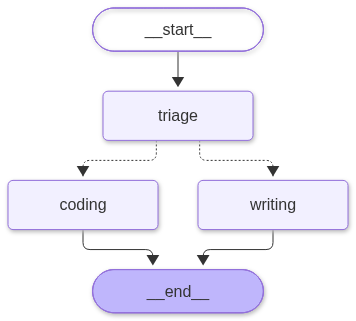

In [6]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_conditional_edges("triage", route_handoff, {"coding": "coding", "writing": "writing"})
builder.add_edge("coding", END)
builder.add_edge("writing", END)
handoff_graph = builder.compile()

handoff_graph

In [7]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request": q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩 담당] 파이썬 for문 설명해줘 > 예제: for x in [1, 2, 3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [8]:
for update in handoff_graph.stream({"request": "파이썬 리스트 예제"}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩 담당] 파이썬 리스트 예제 > 예제: for x in [1, 2, 3]: print(x)'}}


위에는 기본 구조??

In [9]:
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from typing import TypedDict, Literal

In [10]:
llm = ChatOpenAI(model="gpt-5.6-luna", temperature=0)

# 1. 분류 에이전트
def triage(state: HandoffState) -> Command[Literal["coding", "writing"]]: # Literal로 묶어서 에이전트끼리 대화 가능
    text = state["request"].lower()
    dept = "coding" if any(k in text for k in ("파이썬", "코드", "python", "for문")) else "writing"

    # updates: 공유 상태(State)에 department값을 저장. got: 다음에 실행할 노드를 지정
    return Command(update={"department": dept}, goto = dept) # goto해서 에이전트끼리 대화 가능

# 2. 코딩 에이전트
def coding(state: HandoffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}


# 3. 글쓰기 에이전트
def writing(state: HandoffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요.\n요청: {state['request']}"
    )
    return {"answer": response.content}

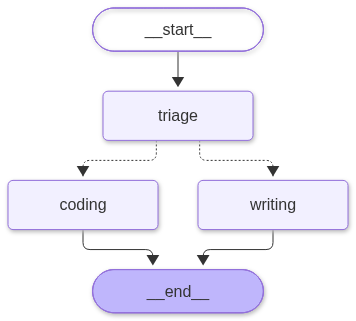

In [11]:
builder = StateGraph(HandoffState)

builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)

builder.add_edge(START, "triage")
builder.add_edge("coding", END)
builder.add_edge("writing", END)

graph = builder.compile()
graph


In [12]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request": q})
    print(f"\n질문: {q}")
    print(f"담당: {result["department"]}")
    print(f"답변: {result["answer"]}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for문`은 **여러 개의 데이터를 하나씩 꺼내 반복 실행할 때** 사용합니다.

## 1. 기본 문법

```python
for 변수 in 반복할_데이터:
    실행할_문장
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "포도"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
포도
```

`fruit` 변수에 리스트의 값이 하나씩 들어갑니다.

---

## 2. 숫자를 반복할 때: `range()`

`range()`는 연속된 숫자를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 4까지**의 숫자를 의미합니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

`range(시작, 끝)`에서 **끝 숫자는 포함되지 않습니다.**

---

## 3. 반복하면서 계산하기

```python
for i in range(1, 6):
    print(i * 2)
```

결과:

```text
2
4
6
8
10
```

---

## 4. 문자열도 반복할 수 있습니다

문자열은 글자를 하나씩 꺼낼 수 있습니다.

```python
for char in "Python":
    print(char)
```

결과:

```text
P
y
t
h
o
n
```

---

## 5. `break`: 반복 중단하기

`break`를 만나면 반복문을 즉시 종료합니다.

```python
for i in range(1, 10):
    if i == 5:
        break
    prin

### 1. Network
각 전문 에이전트로 되어 있으면 직접 이웃 에이전트로 handoff를 함

In [32]:
import matplotlib.pyplot as plt
import os, json
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field

In [ ]:
load_dotenv()

True

In [19]:
if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(".env에 openai api key 설정!")

llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [21]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [ ]:
def ask(system: str, user: str) -> str:
    """시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다."""
    response = llm.invoke([("system", system), ("human", user)])
    return str(response.content)

In [14]:
class ChartState(TypedDict, total=False):
    question: str
    source: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

class ChartData(TypedDict):
    label: str
    value: float

In [23]:
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError("TAVILY KEY ERROR!")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{"title": x.get("title", ""), "url": x.get("url", ""), "content": x.get("content", "")[:1500]} for x in result.get("results", [])]

In [ ]:
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만")
    summary: str

In [27]:
research_llm = llm.with_structured_output(ResearchData)

In [43]:
def researcher(state: ChartState) -> Command[Literal["chart", "__end__"]]:
    sources = search_web(state['question'])
    parsed = research_llm.invoke([
        ("system", "검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요"),
        ("human", json.dumps({"question": state["question"], "sources": sources},
                            ensure_ascii=False))
    ])

    if not parsed.data:
        return Command(update={"sources": sources, "error": "검증 가능한 수치가 없습니다."}, goto = END)

    return Command(update={"sources":sources, "data":[x.model_dump() if hasattr(x, "model_dump") else x for x in parsed.data], "summary": parsed.summary}, goto="chart")


In [50]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)

    # 내가 추가
    # 한글 깨짐 방지
    plt.rcParams["font.family"] = "Malgun Gothic"
    # 마이너스(-) 기호 깨짐 방지
    plt.rcParams["axes.unicode_minus"] = False
    
    return Command(update={"chart_path":str(path)}, goto=END)

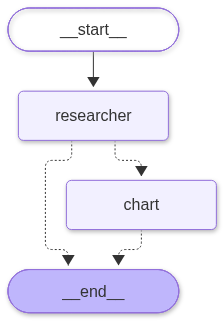

In [45]:
builder = StateGraph(ChartState)
builder.add_node("researcher", researcher)
builder.add_node("chart", chart)
builder.add_edge(START, "researcher")
network_chart = builder.compile()
network_chart

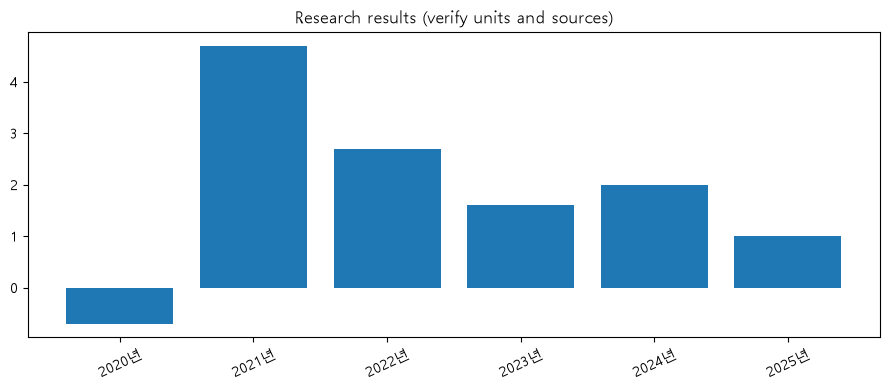

In [51]:
result = network_chart.invoke({"question": "2020년부터 2025까지 한국의 연도별 실질 GDP 성장률(%)"}, config={"recursion_limit": 5})

### 멀티 에이전트 기반(네트워크) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석하여 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템을 개발

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 전달받아 취약 영역에 대한 객관식 문제를 생성

예시
```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}
1. 학생의 학습 점수를 입력 받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. LLM을 이용하여 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. LLM을 이용해 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```